# Homework 1 — Regression

This homework is focused on a complete regression workflow: data preparation, model training, hyperparameter tuning, model selection, and final evaluation.

The homework is worth **15 points**.

- Deadlines and submission rules are listed at [https://courses.fit.cvut.cz/BIE-ML1/homeworks/index.html](https://courses.fit.cvut.cz/BIE-ML1/homeworks/index.html).
- Submit the completed notebook together with the output file `results.csv`.
- Use Markdown cells to briefly explain important decisions and results. Keep the notebook clear and reasonably concise.
- If you submit the homework after the first deadline but before the final deadline, you will receive a penalty of **-7 points**. Submissions after the final deadline will receive no points.

> **The homework is intentionally open-ended in several places. Choosing an appropriate way to solve the individual parts of the task is part of the assignment. Your decisions should be reasonable and briefly justified.**

> **A complete solution should demonstrate sufficient experimentation and understanding of the methods.**

## Data

Your task is to predict the selling price of used cars.

You are given:

- `data.csv` — data containing the target variable `Price`,
- `evaluation.csv` — previously unseen data without `Price`, used for final evaluation.

### Variables

- `ID` — record identifier
- `Make` — car manufacturer
- `Price` — selling price; **target variable**
- `Year` — year of manufacture
- `Kilometer` — mileage in kilometres
- `Fuel Type` — fuel type
- `Transmission` — transmission type
- `Location` — city where the car was sold
- `Color` — car colour
- `Owner` — ownership information
- `Seller Type` — type of seller
- `Engine` — engine displacement
- `Drivetrain` — driven wheels
- `Length` — vehicle length in mm
- `Width` — vehicle width in mm
- `Height` — vehicle height in mm
- `Seating Capacity` — number of seats
- `Fuel Tank Capacity` — fuel tank capacity in litres

Some variables are numerical, some are categorical, some require a simple transformation, and some values are missing.

## Tasks
* Load the data from `data.csv` into the notebook. Split the dataset appropriately into subsets that will be used for model training (training set), model comparison (validation set), and subsequent estimation of the performance of the final model (test set).

* Perform basic data preprocessing:
  * Inspect the individual features and transform them into a suitable form for use with the selected regression models. For example, extract the numerical value from the `Engine` feature.
  * Handle missing values using some simple approach (e.g. replace them with a selected constant or another simple value). *Be careful about methodological errors!*
  * You may also use visualizations where appropriate. Briefly but sufficiently comment on your choices and results.

* Apply **linear regression**, **ridge regression**, and one of the following regression models: **decision tree** or **k-nearest neighbours**. For each model, as appropriate:
  * Comment on the suitability of the model for this type of problem.
  * Experiment with feature scaling (standardization / min-max scaling) if you expect it to have a beneficial effect on the model.
  * Select the main hyperparameter(s) to tune, where applicable, and find suitable values with respect to MSE.
  * For the model with the best hyperparameter values on the validation set, report its MSE.
  * Briefly comment on the obtained results.

* From all the considered models, select the final model and correctly estimate the prediction error, measured by RMSE (i.e. the square root of MSE), that you can expect on new data that have not been available to you so far. *Be careful about methodological errors!*

* Finally, load the evaluation data from `evaluation.csv` and use your final model to compute predictions for these data. Create a file `results.csv` containing the predictions in a column named **Price** and the corresponding identifiers in a column named **ID** (keep these column names exactly). Submit this file together with the notebook.

  An example of the first few rows of `results.csv` (with generally different values of `Price`) is:

```text
ID,Price
548,450000
879,680000
...
```


Store `results.csv` next to this notebook and submit both files.

## What should be explained in the notebook?

You do not need to write long descriptions. Briefly explain:

1. which variables you removed, if any, and why,
2. how you handled categorical and missing values,
3. when and why you used scaling,
4. which hyperparameter values you tried and which were selected,
5. why you selected the final model,
6. what test RMSE you obtained and what it means.


# The imports

In [384]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.linear_model import LinearRegression, Ridge
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, root_mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, accuracy_score
from sklearn.model_selection import ParameterGrid
import seaborn as sns
from sklearn.preprocessing import FunctionTransformer
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor

# Helper functions

In [385]:
def output(y, y_pred):
    print(f"RMSE: {root_mean_squared_error(y_true=y, y_pred=y_pred)}")
    print(f"MSE: {mean_squared_error(y_true=y, y_pred=y_pred)}")
    print(f"R2 score: {r2_score(y, y_pred)}")

    plt.scatter(y, y_pred)
    plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r')
    plt.show()

# Data preparation and processing
## Data preparation
1. Data was loaded into Pandas DataFrame and using the `na_values` parameter I tried to unify the representation of missing value into a standart one.
2. The `ID` feature was dropped as it doesn't carry any useful information for the model and could cause overfitting in some cases.
3. The `Engine` feature was transformed into a float by using RegEx. Float was used because it can carry the NaN, meanwhile int cannot.
4. The data was split into the Xtrain, Xval, and Xtest sets using the 60/20/20 division.

In [386]:
# 1. Data preparation
# 1.1 Load the data from `data.csv` into the notebook.
df = pd.read_csv('data.csv', na_values=["", "?", "N/A", "n/a", "NA", "null", "None", "-", "--", "nan"])

df.drop(["ID"], axis=1, inplace=True)
df.drop('Color', axis=1, inplace=True)
df['Volume'] = df['Length'] * df['Width'] * df['Height']

# Convert Engine to integer
df["Engine"] = df["Engine"].str.extract(r"(\d+)", expand=False).astype(float)

# 1.2 Split the dataset into training set, validation set, test set.
seed = 123

Xdata = df.drop(columns='Price')
ydata = df.Price

Xtrain, Xtemp, ytrain, ytemp = train_test_split(
    Xdata, ydata,
    test_size = 0.4,
    random_state=seed
)

Xval, Xtest, yval, ytest = train_test_split(
    Xtemp, ytemp,
    test_size = 0.5,
    random_state=seed
)

print("train:", Xtrain.shape, ytrain.shape)
print("validation:", Xval.shape, yval.shape)
print("test:", Xtest.shape, ytest.shape)

train: (1009, 16) (1009,)
validation: (337, 16) (337,)
test: (337, 16) (337,)


## Data Processing
1. First things first, I had to deal with the missing values. Removing the data wasn't an option, as in that case, lots of the training data would be left out. So, after exploring the features that contain missing values, I decided to act as follows: if the value is numerical, it would be imputed using the median, and for the text features, a new category, "Unknown", would be added.
2. One-Hot Encoder was used with nominal features, and `transmission` (having only Manual and Automatic, based on my observations) is now binary.
3. After inspecting the `Owner` feature, I found it to be ordinal based on its mean, so I used `OrdinalEncoder` for it.
4. And finally, for `Make` and `Location`, I used `TargetEncoder`. I didn't want to encode them using the One-Hot Encoder because of the number of features they would add, which would almost always be zeros. So, I used `TargetEncoder` instead to link the location and car brand to the average price. And after I applied the log() function to both to match the features with the target which is also logged throughout the models.
5. Later, through experiments with features and their encoding, I found that removing the `Color` feature positively affects the model. (This step was done in the Data Preparation section) 

In [387]:
# 2. Basic data preprocessing
# 2.1 Handle missing values using some simple approach ->  You need imputation that is fit on train, for example SimpleImputer (median for numeric columns, most-frequent or an "Unknown" category for Drivetrain)
# 2.2 Inspect the individual features and transform them into a suitable form for use with the selected regression models.

owner_order = [['4 or More', 'Fourth', 'Third', 'Second', 'First', 'UnRegistered Car']]
const = SimpleImputer(strategy="constant", fill_value="Unknown")
trgt = TargetEncoder(smooth="auto", target_type="continuous", cv=KFold(5, shuffle=True, random_state=seed))

pre = ColumnTransformer([
    ("Numeric imputer", SimpleImputer(strategy="median"), ['Engine', 'Fuel Tank Capacity']),
    ("Nominal One-hot", Pipeline([("Constant imputaion", const), ("One-hot encoding", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.int8))]), ['Drivetrain', 'Fuel Type', 'Seller Type']),
    ("Binary Encoding of Transmission", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False, dtype=np.int8), ['Transmission']),
    ("Ordinal Encoding", OrdinalEncoder(categories=owner_order, handle_unknown="use_encoded_value", unknown_value=-1), ['Owner']),
    ("Target Encoding", Pipeline([("Target Encoder", trgt), ("Log", FunctionTransformer(np.log))]), ['Location', 'Make']),
], remainder="passthrough")

Ctrain = Xtrain
Cval = Xval
Ctest = Xtest

pre.set_output(transform="pandas")
Xtrain = pre.fit_transform(Xtrain, ytrain)
Xval = pre.transform(Xval)
Xtest = pre.transform(Xtest)

pd.concat([Xtrain, Xval, Xtest]).info()


pre_tree = ColumnTransformer([
    ("Numeric imputer", SimpleImputer(strategy="median"), ['Engine', 'Fuel Tank Capacity']),
    ("Nominal One-hot", Pipeline([("Constant imputaion", const), ("One-hot encoding", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.int8))]), ['Drivetrain', 'Fuel Type', 'Seller Type']),
    ("Binary Encoding of Transmission", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False, dtype=np.int8), ['Transmission']),
    ("Ordinal Encoding", OrdinalEncoder(categories=owner_order, handle_unknown="use_encoded_value", unknown_value=-1), ['Owner']),
    ("Target Encoding", trgt, ['Location', 'Make']),
], remainder="passthrough")

pre_tree.set_output(transform="pandas")
Xtrain_tree = pre_tree.fit_transform(Ctrain, ytrain)
Xval_tree = pre_tree.transform(Cval)
Xtest_tree = pre_tree.transform(Ctest)

<class 'pandas.core.frame.DataFrame'>
Index: 1683 entries, 456 to 546
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   tmp_col_name_0_0   1683 non-null   float64
 1   tmp_col_name_0_1   1683 non-null   float64
 2   tmp_col_name_1_0   1683 non-null   int8   
 3   tmp_col_name_1_1   1683 non-null   int8   
 4   tmp_col_name_1_2   1683 non-null   int8   
 5   tmp_col_name_1_3   1683 non-null   int8   
 6   tmp_col_name_1_4   1683 non-null   int8   
 7   tmp_col_name_1_5   1683 non-null   int8   
 8   tmp_col_name_1_6   1683 non-null   int8   
 9   tmp_col_name_1_7   1683 non-null   int8   
 10  tmp_col_name_1_8   1683 non-null   int8   
 11  tmp_col_name_1_9   1683 non-null   int8   
 12  tmp_col_name_1_10  1683 non-null   int8   
 13  tmp_col_name_1_11  1683 non-null   int8   
 14  tmp_col_name_1_12  1683 non-null   int8   
 15  tmp_col_name_1_13  1683 non-null   int8   
 16  tmp_col_name_2_0   1683 non-

# Linear Regression

## Suitability of the model for this type of problem

Predicting the car price is one of the typical examples of a problem that the Linear Regression model can solve. It is a good choice of model as long as there is an actual linear dependence between input features and the target and as long as the training data represents the actual data well (e.g., the training data includes all sorts of cars and not only luxury cars).

## Obtained results

The linear regression model has practically no hyperparameters to tune. The experiment showed that all scalers had little to no effect on the outcome; they all improved the base result significantly. From the target exploration, I found that the data is right-skewed—it led me to apply a log() function to the training targets, which made the data bell-shaped.

These are the obtained measure values:

RMSE: 659144.6360117692
<br>
MSE: 434471651183.0877
<br>
R2 score: 0.8535915561999057

RMSE: 659144.6360117692
MSE: 434471651183.0877
R2 score: 0.8535915561999057


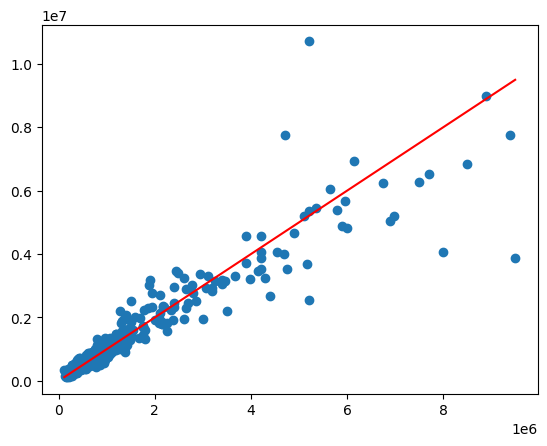

In [388]:
# 3.2 Experiment with feature scaling
# 3.3 Choose hyperparameters to tune and find suitable values with respect to MSE.
scaler = StandardScaler()

Xtrain_scaled = scaler.fit_transform(Xtrain)
Xval_scaled = scaler.transform(Xval)
ytrain_log = np.log(ytrain)
    
clf = LinearRegression()
clf.fit(Xtrain_scaled, ytrain_log)
Y_predict_val = np.exp(clf.predict(Xval_scaled))

output(y=yval, y_pred=Y_predict_val)

# Ridge Regression

## Suitability of the model for this type of problem
The ridge regression fits this problem as well as the linear does, however, additionally to what linear regression does, ridge regression reduces chance of overfitting, handles collinearity, and it is considered to perform better on small/nosiy samples than linear regression. Which is a useful case in this problem, as our dataset consists of multiple features that may be considered collinear, in adittion to that the dataset consists multiple clear outliers (e.g luxary cars in exotic locations).


## Obtained results
Initially the appropriate scaler was chosen - `RobustScaler` performed slightly better then `StandartScaler` and `MinMaxScaler`. The alpha was used through the iterative search over the range of possible values.
<br>
These are the obtained measure values:
<br>
RMSE: 586448.5050158406
<br>
MSE: 343921849035.3145
<br>
R2 score: 0.8841050674560758

RMSE: 586448.5050158406
MSE: 343921849035.3145
R2 score: 0.8841050674560758


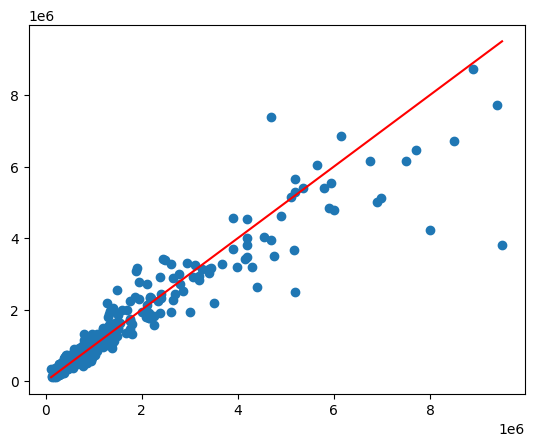

In [389]:
# 4.2 Experiment with feature scaling
# 4.3 Choose hyperparameters to tune and find suitable values with respect to MSE.
# 4.4 For the model with the best hyperparameter values on the validation set report its MSE.
scaler = RobustScaler()

Xtrain_scaled = scaler.fit_transform(Xtrain)
Xval_scaled = scaler.transform(Xval)
ytrain_log = np.log(ytrain)

alphas = np.logspace(-3, 3, 60)
val_rmse = []

for alpha in alphas:
    clf_ridge = Ridge(alpha)
    clf_ridge.fit(Xtrain_scaled, ytrain_log)

    Y_predict_ridge = np.exp(clf_ridge.predict(Xval_scaled))
    val_rmse.append(root_mean_squared_error(y_true=yval, y_pred=Y_predict_ridge))

optimal_alpha = alphas[np.argmin(val_rmse)]
minValue = np.min(val_rmse)

clf_ridge = Ridge(optimal_alpha)
clf_ridge.fit(Xtrain_scaled, ytrain_log)

Y_predict_ridge = np.exp(clf_ridge.predict(Xval_scaled))
output(y=yval, y_pred=Y_predict_ridge)

# Decision tree

## Suitability of the model for this type of problem


## Obtained results

<br>
These are the obtained measure values:
<br>
RMSE:
<br>
MSE:
<br>
R2 score:

{'ccp_alpha': np.float64(100000.0),
 'max_depth': 10,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'splitter': 'random'}

Best val MSE:  441,663,569,835
Best val RMSE: 664,578
Best val R2:   0.851  (train R2: 0.965)


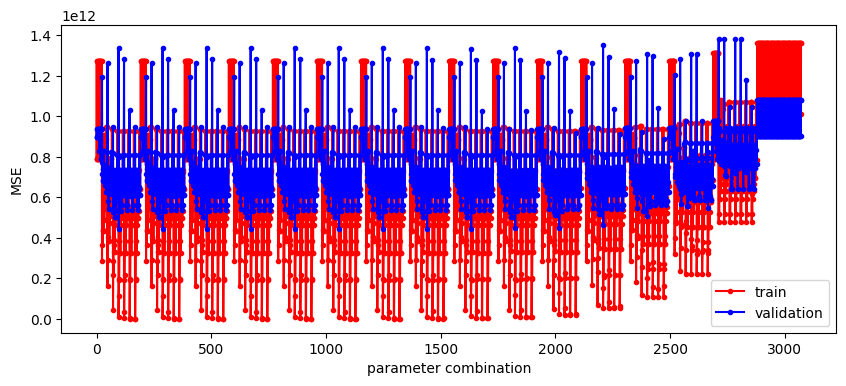

In [390]:
param_grid = {
    'splitter': ['best', 'random'],
    'max_depth': [3, 5, 6, 8, 10, 12, 16, None],
    'min_samples_split': [2, 10, 30],
    'min_samples_leaf': [1, 5, 10, 20],
    'ccp_alpha': np.concatenate([[0], np.logspace(4, 11, 15)])
}
param_comb = list(ParameterGrid(param_grid))

val_mse, train_mse = [], []
val_r2, train_r2 = [], []

for params in param_comb:
    clf_tree = DecisionTreeRegressor(**params, random_state=0)
    clf_tree.fit(Xtrain, ytrain)

    pred_train = clf_tree.predict(Xtrain)
    pred_val = clf_tree.predict(Xval)

    train_mse.append(mean_squared_error(ytrain, pred_train))
    val_mse.append(mean_squared_error(yval, pred_val))
    train_r2.append(r2_score(ytrain, pred_train))
    val_r2.append(r2_score(yval, pred_val))

best_idx = np.argmin(val_mse)
best_params = param_comb[best_idx]
display(best_params)
print(f"Best val MSE:  {val_mse[best_idx]:,.0f}")
print(f"Best val RMSE: {np.sqrt(val_mse[best_idx]):,.0f}")
print(f"Best val R2:   {val_r2[best_idx]:.3f}  (train R2: {train_r2[best_idx]:.3f})")

plt.figure(figsize=(10, 4))
plt.plot(train_mse, 'or-', markersize=3)
plt.plot(val_mse, 'ob-', markersize=3)
plt.xlabel('parameter combination')
plt.ylabel('MSE')
plt.legend(['train', 'validation'])
plt.show()

In [391]:



# 6. From all the considered models, select the final model and correctly estimate the prediction error, measured by RMSE (i.e. the square root of MSE), that you can expect on new data that have not been available to you so far. *Be careful about methodological errors!*

# 7. Final evaluation
# 7.1 Load the evaluation data from `evaluation.csv`
# 7.2 Use your final model to compute predictions for these data.
# 7.3 Create a file `results.csv` containing the predictions in a column named **Price** and the corresponding identifiers in a column named **ID** (keep these column names exactly).
# 7.4 Submit this file together with the notebook.